# 05 - Final models, interpretation and test labels

**Goal:** fit the models chosen in notebook 04 on all training students, understand what they learned and where they fail, and produce the labels for the test set.

**Inputs:** `data/raw/*.csv` through `miopia.data.load_raw()`, `final_model` from `miopia.models`, and the estimates saved in `results/experiments/nested_protocol.json`.

**Outputs:** `results/test_labels.txt` and the figures `05_*.png`.

**Assumptions touched:** A1 and A2 (format of the labels), B1, B2, B3, B4, B9, B13, B14, B15, B16 and B17, see `docs/assumptions.md`. **Test students are predicted only in section 5.** Afterwards their predictions and measurements are only described, and no label, threshold or model changes. Earlier notebooks looked at test features only for cleaning checks and a shift check, section 5 adds input checks, and nothing was fitted on them. `MM` is trained on the corrected labels (B2). We do not have the test labels.

## 1. Setup and data loading

In [1]:
import json

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from scipy.stats import binom, fisher_exact
from sklearn.base import clone
from sklearn.inspection import permutation_importance
from sklearn.metrics import confusion_matrix
from sklearn.model_selection import RepeatedStratifiedKFold

from miopia.config import RANDOM_STATE, RESULTS
from miopia.data import load_raw
from miopia.features import clean_features, with_axial_corneal_ratio
from miopia.models import final_model
from miopia.plotting import BLUE, SEQUENTIAL_CMAP, save_fig, set_style
from miopia.validation import correct_mm_labels, evaluate, make_strata

set_style()
pd.set_option("display.width", 160)
TARGETS = ["M", "MM", "Combo", "DCombo"]
RATIO = "axial_corneal_ratio"
X_train_raw, Y_provided, X_test_raw = load_raw()
Y_train = correct_mm_labels(Y_provided)     # B2: the 8 inconsistent MM labels corrected
clean_train = clean_features(X_train_raw)
FEATURES = list(clean_train.columns)
X_train = with_axial_corneal_ratio(clean_train)
print(f"train {X_train.shape}")

train (132, 33)


## 2. What are the final models?

**What and why:** each model from `final_model` is fitted on all 132 training students, because more students give a better final model. The hyperparameters of the `MM` XGBoost and the `Combo` forest are chosen again inside these students. The scores quoted come from cross-validation in notebook 04, not from these fits.

In [2]:
fitted, columns = {}, {}
for target in TARGETS:
    model, columns[target] = final_model(target, FEATURES)
    fitted[target] = model.fit(X_train[columns[target]], Y_train[target])

def settings(search):
    return {k.removeprefix("model__"): v for k, v in search.best_params_.items()}
print("MM XGBoost settings:", settings(fitted["MM"]))
print("Combo forest settings:", settings(fitted["Combo"]))
pd.DataFrame({
    "M": ["Logistic regression", "axial length + ratio", "threshold 0.5", "notebook 04, section 6"],
    "MM": ["XGBoost", "32 features", f"tuned, depth {fitted['MM'].best_params_['model__max_depth']}; threshold 0.5", "notebook 04, sections 5 and 8"],
    "Combo": ["Random forest", "32 features + ratio", f"tuned, {fitted['Combo'].best_params_['model__max_features']} of features per split", "notebook 04, section 6"],
    "DCombo": ["Logistic regression", "axial length + ratio", "threshold-free, most likely class", "notebook 04, section 6"],
}, index=["model", "inputs", "decision", "justified in"]).T

MM XGBoost settings: {'learning_rate': 0.03, 'max_depth': 2, 'n_estimators': 300}
Combo forest settings: {'max_features': 0.5, 'min_samples_leaf': 1}


,model,inputs,decision,justified in
M,Logistic regression,axial length + ratio,threshold 0.5,"notebook 04, section 6"
MM,XGBoost,32 features,"tuned, depth 2; threshold 0.5","notebook 04, sections 5 and 8"
Combo,Random forest,32 features + ratio,"tuned, 0.5 of features per split","notebook 04, section 6"
DCombo,Logistic regression,axial length + ratio,"threshold-free, most likely class","notebook 04, section 6"


**Findings.** Each target has its own model, as the brief allows, and each row points to where it is justified. The `Combo` forest is the least firmly chosen (notebook 04, section 11).

## 3. What did the models learn?

**What and why:** the `M` and `DCombo` models are logistic regressions on two standardised inputs, so their coefficients can be read directly: a larger size means a stronger association per standard deviation. For `DCombo` there is one row per class. Axial length and the ratio are correlated, so each coefficient must be read with the other held fixed.

In [3]:
rows = {"M, says SI": dict(zip(columns["M"], fitted["M"].named_steps["model"].coef_[0]))}
dcombo = fitted["DCombo"].named_steps["model"]
rows.update({f"DCombo, says {c}": dict(zip(columns["DCombo"], dcombo.coef_[i])) for i, c in enumerate(dcombo.classes_)})
print(f"Spearman correlation of axial length and ratio: {X_train[['axial_length', RATIO]].corr(method='spearman').iloc[0, 1]:.2f}")
pd.DataFrame(rows).T.round(2)

Spearman correlation of axial length and ratio: 0.72


,axial_length,axial_corneal_ratio
"M, says SI",0.89,1.85
"DCombo, says C",-1.65,-1.73
"DCombo, says M1",-1.07,-0.45
"DCombo, says M2",-0.05,0.95
"DCombo, says MM",2.78,1.23


The `Combo` forest and the `MM` XGBoost have no coefficients, so we measure permutation importance: how much balanced accuracy drops on validation students when one feature is shuffled. Each model and its settings are refitted in each training fold. The figure shows `Combo` (one dot per validation fold); the table after it shows `MM`. Near-duplicate features share their importance (notebook 02).

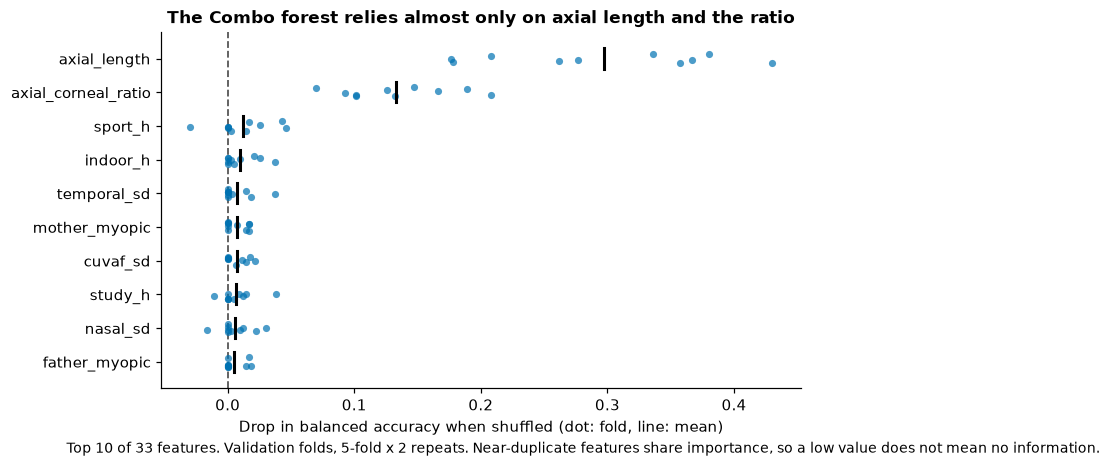

,mean drop in balanced accuracy
axial_length,0.297
axial_corneal_ratio,0.133
sport_h,0.012
indoor_h,0.010
temporal_sd,0.007
mother_myopic,0.007
cuvaf_sd,0.007
study_h,0.007
nasal_sd,0.006
father_myopic,0.005


In [4]:
y_combo = Y_train["Combo"]
data = X_train[columns["Combo"]]
importances = []
for train, val in RepeatedStratifiedKFold(n_splits=5, n_repeats=2, random_state=RANDOM_STATE).split(data, y_combo):
    model = clone(final_model("Combo", FEATURES)[0]).fit(data.iloc[train], y_combo.iloc[train])
    result = permutation_importance(model, data.iloc[val], y_combo.iloc[val], scoring="balanced_accuracy", n_repeats=10, random_state=RANDOM_STATE, n_jobs=-1)
    importances.append(pd.Series(result.importances_mean, index=data.columns))
importances = pd.DataFrame(importances)
order = importances.mean().sort_values(ascending=False).index[:10]

rng = np.random.default_rng(0)
fig, ax = plt.subplots(figsize=(7.5, 4.2))
for y, feature in enumerate(order):
    ax.scatter(importances[feature], y + rng.uniform(-0.15, 0.15, len(importances)), s=22, color=BLUE, alpha=0.7, linewidths=0)
    ax.plot([importances[feature].mean()] * 2, [y - 0.3, y + 0.3], color="black", lw=2)
ax.axvline(0, color="0.35", ls="--", lw=1.2, zorder=0)
ax.set_yticks(range(len(order)), order)
ax.invert_yaxis()
ax.set_xlabel("Drop in balanced accuracy when shuffled (dot: fold, line: mean)")
ax.set_title('The Combo forest relies almost only on axial length and the ratio')
fig.text(0.01, -0.03, f"Top 10 of {data.shape[1]} features. Validation folds, 5-fold x 2 repeats. Near-duplicate features share importance, so a low value does not mean no information.", fontsize=9)
save_fig(fig, "05_combo_importance")
plt.show()
importances.mean().sort_values(ascending=False).head(10).round(3).to_frame("mean drop in balanced accuracy")

In [5]:
y_mm = Y_train["MM"]
data_mm = X_train[columns["MM"]]
mm_importances = []
for train, val in RepeatedStratifiedKFold(n_splits=5, n_repeats=2, random_state=RANDOM_STATE).split(data_mm, y_mm):
    model = clone(final_model("MM", FEATURES)[0]).fit(data_mm.iloc[train], y_mm.iloc[train])
    result = permutation_importance(model, data_mm.iloc[val], y_mm.iloc[val], scoring="balanced_accuracy", n_repeats=10, random_state=RANDOM_STATE, n_jobs=-1)
    mm_importances.append(pd.Series(result.importances_mean, index=data_mm.columns))
pd.DataFrame(mm_importances).mean().sort_values(ascending=False).head(10).round(3).to_frame("MM: mean drop in balanced accuracy")

,MM: mean drop in balanced accuracy
axial_length,0.396
sport_h,0.002
kerato_od_axis2,0.000
mother_myopic,0.000
study_h,0.000
indoor_h,0.000
female,0.000
age,0.000
relatives_unknown,0.000
indoor_much,0.000


**Findings.** The models tell a simple and consistent story: myopia rises with a longer eye and a higher axial/corneal ratio. On `DCombo`, both coefficients go from clearly negative for controls to clearly positive for myopia magna. The `Combo` forest gets almost all of its performance from axial length and the ratio, and the `MM` XGBoost almost only from axial length: shuffling it drops balanced accuracy by 0.40, while no other feature moves it by more than 0.01. This does not mean that family history or time outdoors have no effect: with 132 students, these may act through the length of the eye, which is measured directly. Coefficients and importances describe what the models use, not causes.

## 4. Where do the final models fail?

**What and why:** errors are measured on validation students, with the same 5-fold, 10-repeat scheme, so that no student is judged by a model that was trained on them. The panels show, for each true class, the share of predictions given to each class and the mean number of students per repeat.

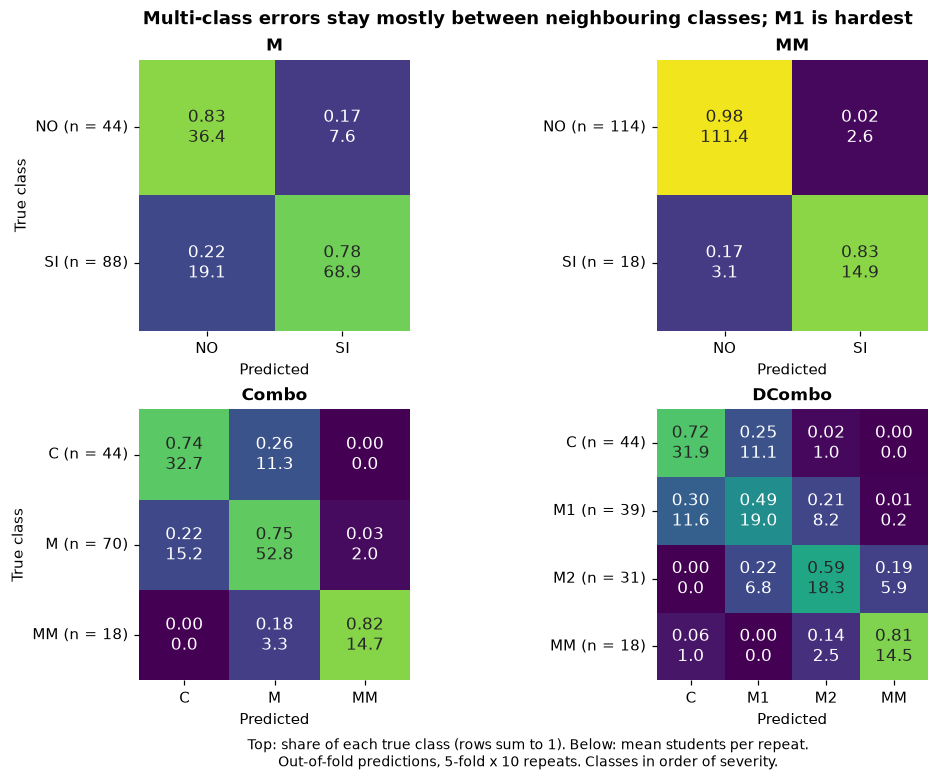

In [6]:
frames, predictions = {}, {}
for target in TARGETS:
    model, cols = final_model(target, FEATURES)
    frames[target], predictions[target] = evaluate(model, X_train[cols], Y_train[target], Y_train[target], make_strata(Y_train, target))

fig, axes = plt.subplots(2, 2, figsize=(9.5, 7), layout="constrained")
for ax, target in zip(axes.ravel(), TARGETS):
    classes = sorted(Y_train[target].unique())
    truth = np.repeat(Y_train[target].to_numpy(), predictions[target].shape[1])
    per_repeat = confusion_matrix(truth, predictions[target].ravel(), labels=classes) / predictions[target].shape[1]
    rates = per_repeat / per_repeat.sum(axis=1, keepdims=True)
    annotation = np.array([[f"{r:.2f}\n{c:.1f}" for r, c in zip(rate_row, count_row)] for rate_row, count_row in zip(rates, per_repeat)])
    sns.heatmap(rates, annot=annotation, fmt="", annot_kws={"fontsize": 11}, cmap=SEQUENTIAL_CMAP, vmin=0, vmax=1, cbar=False, square=True, xticklabels=classes, yticklabels=classes, ax=ax)
    for label, rate in zip(ax.texts, rates.ravel()):
        label.set_color("0.15" if rate >= 0.5 else "white")
    counts = Y_train[target].value_counts()
    ax.set_yticklabels([f"{c} (n = {counts[c]})" for c in classes], rotation=0)
    ax.set_xlabel("Predicted")
    ax.set_title(target)
for ax in axes[:, 0]:
    ax.set_ylabel("True class")
fig.suptitle('Multi-class errors stay mostly between neighbouring classes; M1 is hardest', fontweight="bold")
fig.supxlabel("Top: share of each true class (rows sum to 1). Below: mean students per repeat.\nOut-of-fold predictions, 5-fold x 10 repeats. Classes in order of severity.", fontsize=9)
save_fig(fig, "05_confusion")
plt.show()

Since the classes of `DCombo` are ordered, the first table shows how far its errors go. The second shows how the `M` errors spread over the severity groups, and whether they concentrate near the boundary.

In [7]:
position = {c: i for i, c in enumerate(["C", "M1", "M2", "MM"])}
distance = np.abs(np.vectorize(position.get)(predictions["DCombo"]) - Y_train["DCombo"].map(position).to_numpy()[:, None])
display(pd.Series({"correct": (distance == 0).mean(), "off by one class": (distance == 1).mean(), "off by two or more": (distance >= 2).mean()}, name="DCombo predictions").round(2).to_frame())

wrong = predictions["M"] != Y_train["M"].to_numpy()[:, None]
pd.DataFrame({"students": Y_train.groupby("DCombo").size(), "mean ratio": X_train.groupby(Y_train["DCombo"])[RATIO].mean(),
              "M error rate": pd.Series(wrong.mean(axis=1), index=Y_train.index).groupby(Y_train["DCombo"]).mean()}).round(2)

,DCombo predictions
correct,0.63
off by one class,0.35
off by two or more,0.02


,students,mean ratio,M error rate
DCombo,,,
C,44,3.01,0.17
M1,39,3.10,0.46
M2,31,3.23,0.00
MM,18,3.32,0.06


**Findings.** Most errors fall between neighbouring classes. On `DCombo`, about one prediction in three is off by one class and very few by more. `M1` is the hardest class: its mean ratio lies between those of controls and `M2`, and the `M` model calls almost half of the `M1` students not myopic, while it never misses an `M2` student. The boundary between `M1` and no myopia is the weakest point of these measurements, perhaps because there is no direct measure of refraction. On `MM`, the model finds about four positives in five and gives very few false alarms. A tuned threshold did not improve this balance (notebook 04, section 8); a clinical use that weighs a missed case more could still prefer a lower one.

## 5. What are the labels for the test set?

**What and why:** this is the only place where the test students are predicted. The same row-wise cleaning is applied to them, and anything that was learned, such as medians, scaling, thresholds and hyperparameters, comes from the training students. The file follows A1 and A2: one column per target, separated by tabs, with a header and one row per test student in the order of `X_test.csv`, and the labels written as in `Y_train.csv` (`SI`/`NO`), although the brief says YES/NO. Individual predictions are not printed here, to keep student data out of the report.

**Input checks on the test features.** The test set has no labels, so a wrong label cannot be detected there. Its features can still hold the same kinds of entry error found in train (notebooks 01 and 02). Each check compares a test row with a fixed rule or with the range seen in train: nothing is fitted, no label is produced, and no row is printed.

In [8]:
num_raw = X_train_raw.select_dtypes("number").columns
low, high = X_train_raw[num_raw].min(), X_train_raw[num_raw].max()
both_eyes = lambda col: (X_test_raw[f"OD-{col}"] + X_test_raw[f"OS-{col}"]) / 2  # noqa: E731
input_checks = {
    "fototipo holds a Grupo fot letter (E/L)": X_test_raw["fototipo"].astype(str).str.strip().str.upper().isin(["E", "L"]),
    "LA Media is not the mean of both eyes (> 0.05 mm)": (X_test_raw["LA Media"] - (X_test_raw["LA OD"] + X_test_raw["LA OS"]) / 2).abs() > 0.05,
    "CUVAF-Media is not the mean of OD and OS (> 0.05)": (X_test_raw["CUVAF-Media"] - both_eyes("Media")).abs() > 0.05,
    "duplicated row": X_test_raw.duplicated(),
}
for col in num_raw:
    outside = (X_test_raw[col] < low[col]) | (X_test_raw[col] > high[col])
    if outside.any():
        input_checks[f"{col}: outside the training range"] = outside
pd.Series({k: int(v.sum()) for k, v in input_checks.items()}, name=f"test students, of {len(X_test_raw)}").to_frame()

,"test students, of 24"
fototipo holds a Grupo fot letter (E/L),5
LA Media is not the mean of both eyes (> 0.05 mm),0
CUVAF-Media is not the mean of OD and OS (> 0.05),1
duplicated row,0
hº estudiar sem: outside the training range,1


**Findings.** Five test students have the same `fototipo` mix-up as in train; phototype is not a feature (B9), so it does not reach the models. The CUVAF mean of one student does not match its components, as notebook 02 found; that column is dropped. One student reports more weekly study hours than anyone in train. It may be a typing error or a real value, and nothing shows which, so it is left as it is: `study_h` matters little to the final models (section 3), and only the `Combo` forest uses it. The axial lengths, which drive every model, are consistent. *Decision: no test value is changed.*

In [9]:
X_test = with_axial_corneal_ratio(clean_features(X_test_raw))
test_labels = pd.DataFrame({t: fitted[t].predict(X_test[columns[t]]) for t in TARGETS})
path = RESULTS / "test_labels.txt"
test_labels.to_csv(path, sep="\t", index=False)

check = pd.read_csv(path, sep="\t")
assert check.equals(test_labels) and len(check) == len(X_test_raw) and list(check.columns) == TARGETS
for target in TARGETS:
    assert set(check[target]) <= set(Y_train[target]), target
print(f"wrote {path.name}: {len(check)} rows, columns {list(check.columns)}, no missing values: {check.notna().all().all()}")

wrote test_labels.txt: 24 rows, columns ['M', 'MM', 'Combo', 'DCombo'], no missing values: True


Two checks on the file, neither of which changes any label. The first compares the predicted share of each class with its share in the training labels, since a very different mix would point to a problem. The second counts the contradictions between targets promised in notebook 04, with no prediction forced to agree (B3).

In [10]:
shares = pd.concat({t: pd.DataFrame({"test, predicted": test_labels[t].value_counts(normalize=True),
                                     "train, true": Y_train[t].value_counts(normalize=True)}) for t in TARGETS}).fillna(0).round(2)
display(shares)

m, mm, combo, dc = (test_labels[t] for t in TARGETS)
contradictions = {
    "M = NO but Combo is not C": (m == "NO") & (combo != "C"),
    "M = SI but Combo = C": (m == "SI") & (combo == "C"),
    "MM = SI but Combo is not MM": (mm == "SI") & (combo != "MM"),
    "MM = SI but M = NO": (mm == "SI") & (m == "NO"),
    "Combo and DCombo disagree on C": (combo == "C") != (dc == "C"),
    "Combo and DCombo disagree on MM": (combo == "MM") != (dc == "MM"),
    "M = NO but DCombo is not C": (m == "NO") & (dc != "C"),
    "M = SI but DCombo = C": (m == "SI") & (dc == "C"),
    "MM = SI but DCombo is not MM": (mm == "SI") & (dc != "MM"),
    "For information: Combo = MM and MM = NO": (combo == "MM") & (mm == "NO"),
}
counts = pd.Series({k: int(v.sum()) for k, v in contradictions.items()}, name=f"test students, of {len(test_labels)}")
real = [v for k, v in contradictions.items() if not k.startswith("For information")]
counts["Students with at least one contradiction"] = int(pd.concat(real, axis=1).any(axis=1).sum())
counts.to_frame()

test, predicted  train, true
M      SI             0.54         0.67
       NO             0.46         0.33
MM     NO             0.79         0.86
       SI             0.21         0.14
Combo  C              0.42         0.33
       M              0.42         0.53
       MM             0.17         0.14
DCombo C              0.42         0.33
       M1             0.21         0.30
       M2             0.17         0.23
       MM             0.21         0.14

,"test students, of 24"
M = NO but Combo is not C,1
M = SI but Combo = C,0
MM = SI but Combo is not MM,1
MM = SI but M = NO,0
Combo and DCombo disagree on C,2
Combo and DCombo disagree on MM,1
M = NO but DCombo is not C,1
M = SI but DCombo = C,0
MM = SI but DCombo is not MM,0
For information: Combo = MM and MM = NO,0


The predicted share of `MM = SI` is above the training share, so the next cell compares train and test measurements. Nothing here changes a label: adjusting them after looking at the test set would break the rule of this notebook.

In [11]:
keratometry = ["kerato_od", "kerato_od_axis2", "kerato_os", "kerato_os_axis2"]
measures = pd.DataFrame({"train": [X_train["axial_length"].mean(), X_train[keratometry].mean(axis=1).mean(), X_train[RATIO].mean()],
                         "test": [X_test["axial_length"].mean(), X_test[keratometry].mean(axis=1).mean(), X_test[RATIO].mean()]},
                        index=["axial length (mm)", "keratometry (D)", "ratio"]).round(2)
display(measures)
# The training share predicted SI comes from the out-of-fold predictions of section 4, not from the fit on all students
n_positive, rate = int((test_labels["MM"] == "SI").sum()), (predictions["MM"] == "SI").mean()
predicted_train = round(rate * len(X_train))
_, p_value = fisher_exact([[n_positive, len(test_labels) - n_positive], [predicted_train, len(X_train) - predicted_train]])
print(f"Share predicted MM = SI: test {n_positive / len(test_labels):.2f}, training students out of fold {rate:.2f}, training labels {(Y_train['MM'] == 'SI').mean():.2f}")
print(f"Chance of {n_positive} or more of {len(test_labels)}, taking the out-of-fold rate of {rate:.2f} as known: {binom.sf(n_positive - 1, len(test_labels), rate):.2f}")
print(f"Fisher's exact test of {n_positive}/{len(test_labels)} against {predicted_train}/{len(X_train)}: p = {p_value:.2f}")

,train,test
axial length (mm),24.41,24.56
keratometry (D),43.30,43.03
ratio,3.13,3.13


Share predicted MM = SI: test 0.21, training students out of fold 0.13, training labels 0.14
Chance of 5 or more of 24, taking the out-of-fold rate of 0.13 as known: 0.21
Fisher's exact test of 5/24 against 18/132: p = 0.36


**Findings.** The file has the expected shape and only valid labels. Three of the 24 students have at least one contradiction between targets, mostly `Combo` and `DCombo` disagreeing on controls or myopia magna; no student has `MM = SI` with `M = NO`. They are left as predicted (B3).

`MM = SI` is predicted for 5 of 24 test students (0.21), against 0.13 of training students out of fold. Train and test have similar mean axial length, keratometry and ratio, and Fisher's test (p = 0.36) finds the difference compatible with chance in 24 students. It may also reflect more severe cases, false alarms, or students like the 8 corrected by B2, whose `MM` label depends on how the test column is written. *Decision: the labels stay as predicted.*

## 6. What accuracy should we expect on the test set?

**What and why:** accuracy is what the test labels are graded on, so here is a range for each target before they are graded. *Cross-validation* scores the final model chosen on all students, which is optimistic. *Whole selection* repeats the choice inside each fold (notebook 04, section 11), which is more sober, although the choice varies between folds. On `Combo` it uses a simpler forest and never picks the forest with the ratio, so it describes the process and not the chosen model. The 95% range is what sampling alone allows on 24 students, around the cross-validation score. One student is worth about 0.04.

In [12]:
nested = json.loads((RESULTS / "experiments" / "nested_protocol.json").read_text())["means"]
expected = pd.DataFrame({t: {"majority class": Y_train[t].value_counts(normalize=True).max(),
                             "cross-validation, final model": frames[t]["accuracy"].mean(),
                             "whole selection": nested[t]["whole protocol accuracy"],
                             "axial logistic": nested[t]["axial logistic accuracy"],
                             "balanced accuracy, final model": frames[t]["balanced_accuracy"].mean(),
                             "macro-F1, final model": frames[t]["macro_f1"].mean()} for t in TARGETS}).T.round(2)
n_test = len(test_labels)
expected["95% range, correct of 24"] = [" to ".join(str(int(v)) for v in binom.interval(0.95, n_test, frames[t]["accuracy"].mean())) for t in TARGETS]
expected

,majority class,"cross-validation, final model",whole selection,axial logistic,"balanced accuracy, final model","macro-F1, final model","95% range, correct of 24"
M,0.67,0.80,0.79,0.77,0.80,0.78,15 to 23
MM,0.86,0.96,0.97,0.88,0.90,0.90,21 to 24
Combo,0.53,0.76,0.68,0.65,0.77,0.77,14 to 22
DCombo,0.33,0.63,0.57,0.55,0.65,0.64,11 to 20


**Findings.** On all four targets, both estimates are above the majority class; on `MM` clearly so (0.96 and 0.97 against 0.86). The gain over axial logistic is small for `DCombo` and `Combo` in the whole-selection column, and notebook 04 found the `Combo` evidence weak. With 24 students, sampling alone moves a score by about 4 students on `M`, `Combo` and `DCombo` and by about 2 on `MM`, so one test score cannot settle which model was best.

## 7. Summary

| # | Finding | Decision / action |
|---|---|---|
| 1 | The models rely on axial length and the axial/corneal ratio; the `MM` XGBoost almost only on axial length | Described as what the models use, not as causes |
| 2 | Most errors fall between neighbouring classes, and `M1` is the hardest | Reported; the lack of a direct measure of refraction may be part of the reason |
| 3 | `MM` finds about four positives in five, with very few false alarms | Kept at threshold 0.5: no tuned threshold passed in notebook 04 |
| 4 | `results/test_labels.txt` is written; 3 of the 24 students have contradictions between targets | Left as predicted (B3) and reported |
| 5 | `MM = SI` is predicted for 5 of 24 test students, above the training share; compatible with chance | Not changed; a risk for `MM` accuracy |
| 6 | Both accuracy estimates are above the majority class on every target; sampling alone moves a score by several students | The range in section 6 is what we state before grading |

Test students were predicted only in section 5, and no label, threshold or model changed afterwards. The file format follows A1 and A2, which remain assumptions.

**Next:** slides, the video and the submission package.